## Investigating L Train Baseline Windows

Compare 10, 20, and 60 weekday baselines using 2025 development data.

Investigate where the windows disagree and whether short windows adapt too quickly to sustained changes. Examine both the baseline and the alert boundary, which equals the baseline plus the slow threshold.

Start with two stretches selected from the SQL profiling results that had the most disagreements
- Broadway Junction to Bushwick Av-Aberdeen St (northbound)
- East 105 St to New Lots Av (northbound)

In [1]:
from getpass import getpass

import matplotlib.pyplot as plt
import pandas as pd
from sqlalchemy import URL, create_engine, text

connection_url = URL.create(
    drivername="postgresql+psycopg",
    username="postgres",
    password=getpass("PostgreSQL password: "),
    host="localhost",
    port=5432,
    database="l_train_monitor",
)

engine = create_engine(connection_url)

### Load data

In [2]:
query = text("""
    SELECT
        service_date,
        a_stop,
        b_stop,
        a_station,
        b_station,
        baseline_window_weekdays,
        travel_seconds,
        baseline_seconds,
        slow_threshold_seconds,
        baseline_seconds + slow_threshold_seconds AS alert_boundary_seconds,
        is_slow_day
    FROM public.l_train_baseline_candidates
    WHERE analysis_period = 'development'
      AND (a_stop, b_stop) IN (
          ('L22N', 'L21N'),
          ('L28N', 'L27N')
      )
    ORDER BY a_stop, b_stop, service_date, baseline_window_weekdays
""")

with engine.connect() as connection:
    candidates = pd.read_sql_query(
        query,
        connection,
        parse_dates=["service_date"],
    )

print(f"Loaded {len(candidates):,} candidate rows")

candidates.groupby(
    ["a_stop", "b_stop", "baseline_window_weekdays"]
).agg(
    rows=("service_date", "size"),
    first_date=("service_date", "min"),
    last_date=("service_date", "max"),
    missing_travel_times=("travel_seconds", lambda values: values.isna().sum()),
)

Loaded 1,566 candidate rows


rows first_date  last_date  \
a_stop b_stop baseline_window_weekdays                               
L22N   L21N   10                         261 2025-01-01 2025-12-31   
              20                         261 2025-01-01 2025-12-31   
              60                         261 2025-01-01 2025-12-31   
L28N   L27N   10                         261 2025-01-01 2025-12-31   
              20                         261 2025-01-01 2025-12-31   
              60                         261 2025-01-01 2025-12-31   

                                        missing_travel_times  
a_stop b_stop baseline_window_weekdays                        
L22N   L21N   10                                           0  
              20                                           0  
              60                                           0  
L28N   L27N   10                                           0  
              20                                           0  
              60                                           0

### Investigate Broadway Junction → Bushwick Av-Aberdeen St (northbound)

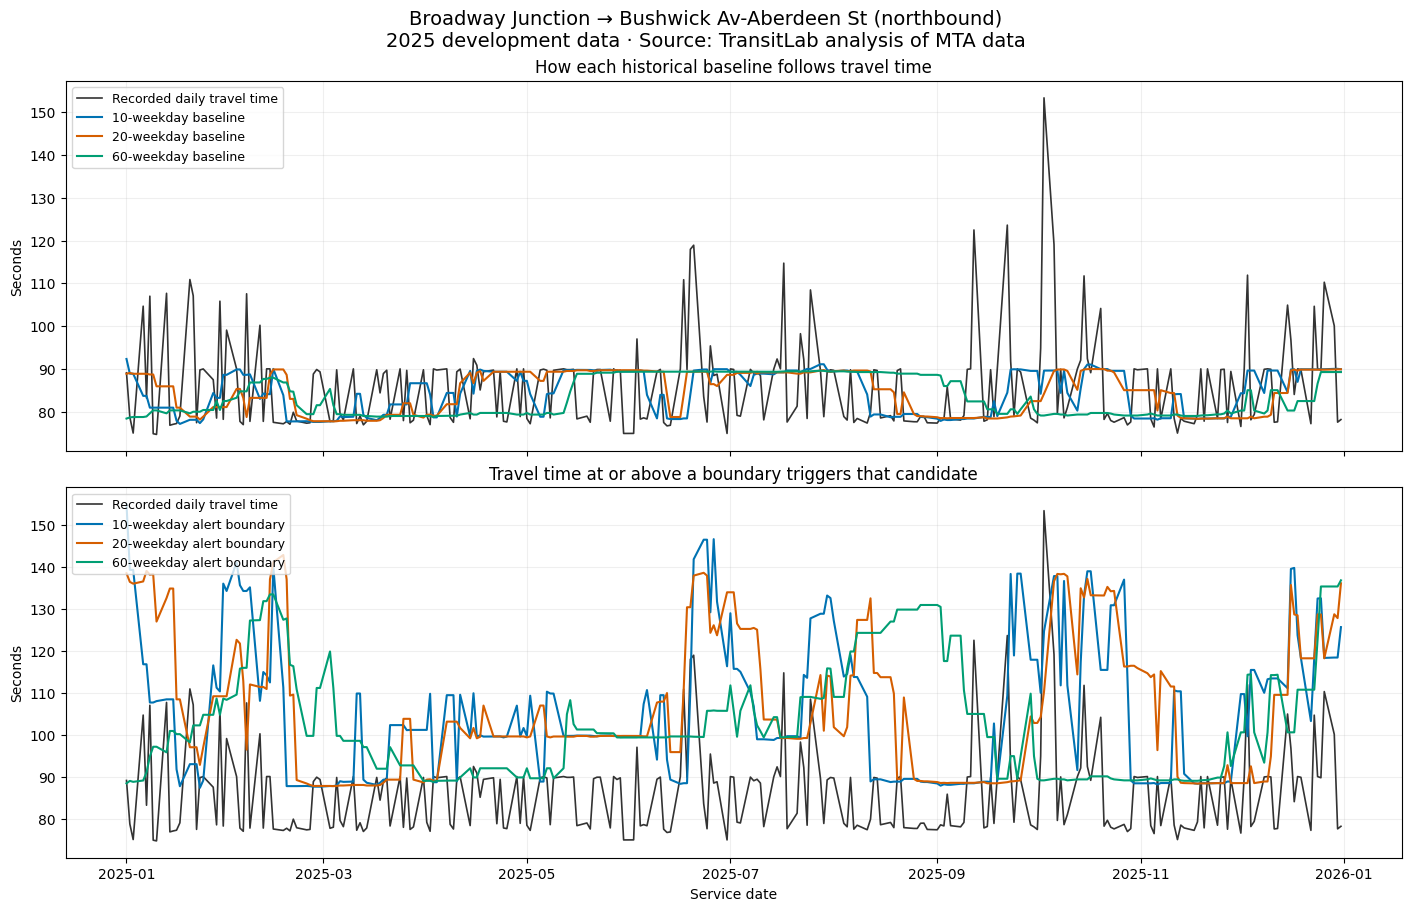

In [7]:
selected_a_stop = "L22N"
selected_b_stop = "L21N"

start_date = "2025-01-01"
end_date = "2025-12-31"

segment = candidates.loc[
    (candidates["a_stop"] == selected_a_stop)
    & (candidates["b_stop"] == selected_b_stop)
    & candidates["service_date"].between(start_date, end_date)
].copy()

if segment.empty:
    raise ValueError("No observations match the selected segment and dates.")

observed = (
    segment[["service_date", "travel_seconds"]]
    .drop_duplicates()
    .sort_values("service_date")
)

station_names = segment.iloc[0]

colors = {
    10: "#0072B2",
    20: "#D55E00",
    60: "#009E73",
}

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True,
    constrained_layout=True,
)

for axis in axes:
    axis.plot(
        observed["service_date"],
        observed["travel_seconds"],
        color="#333333",
        linewidth=1.2,
        label="Recorded daily travel time",
    )
    axis.set_ylabel("Seconds")
    axis.grid(alpha=0.2)

for window, color in colors.items():
    window_data = segment.loc[
        segment["baseline_window_weekdays"] == window
    ].sort_values("service_date")

    axes[0].plot(
        window_data["service_date"],
        window_data["baseline_seconds"],
        color=color,
        linewidth=1.5,
        label=f"{window}-weekday baseline",
    )

    axes[1].plot(
        window_data["service_date"],
        window_data["alert_boundary_seconds"],
        color=color,
        linewidth=1.5,
        label=f"{window}-weekday alert boundary",
    )

axes[0].set_title("How each historical baseline follows travel time")
axes[1].set_title("Travel time at or above a boundary triggers that candidate")
axes[1].set_xlabel("Service date")

for axis in axes:
    axis.legend(loc="upper left", fontsize=9)

fig.suptitle(
    f"{station_names['a_station']} → {station_names['b_station']} (northbound)\n"
    "2025 development data · Source: TransitLab analysis of MTA data",
    fontsize=14,
)

plt.show()

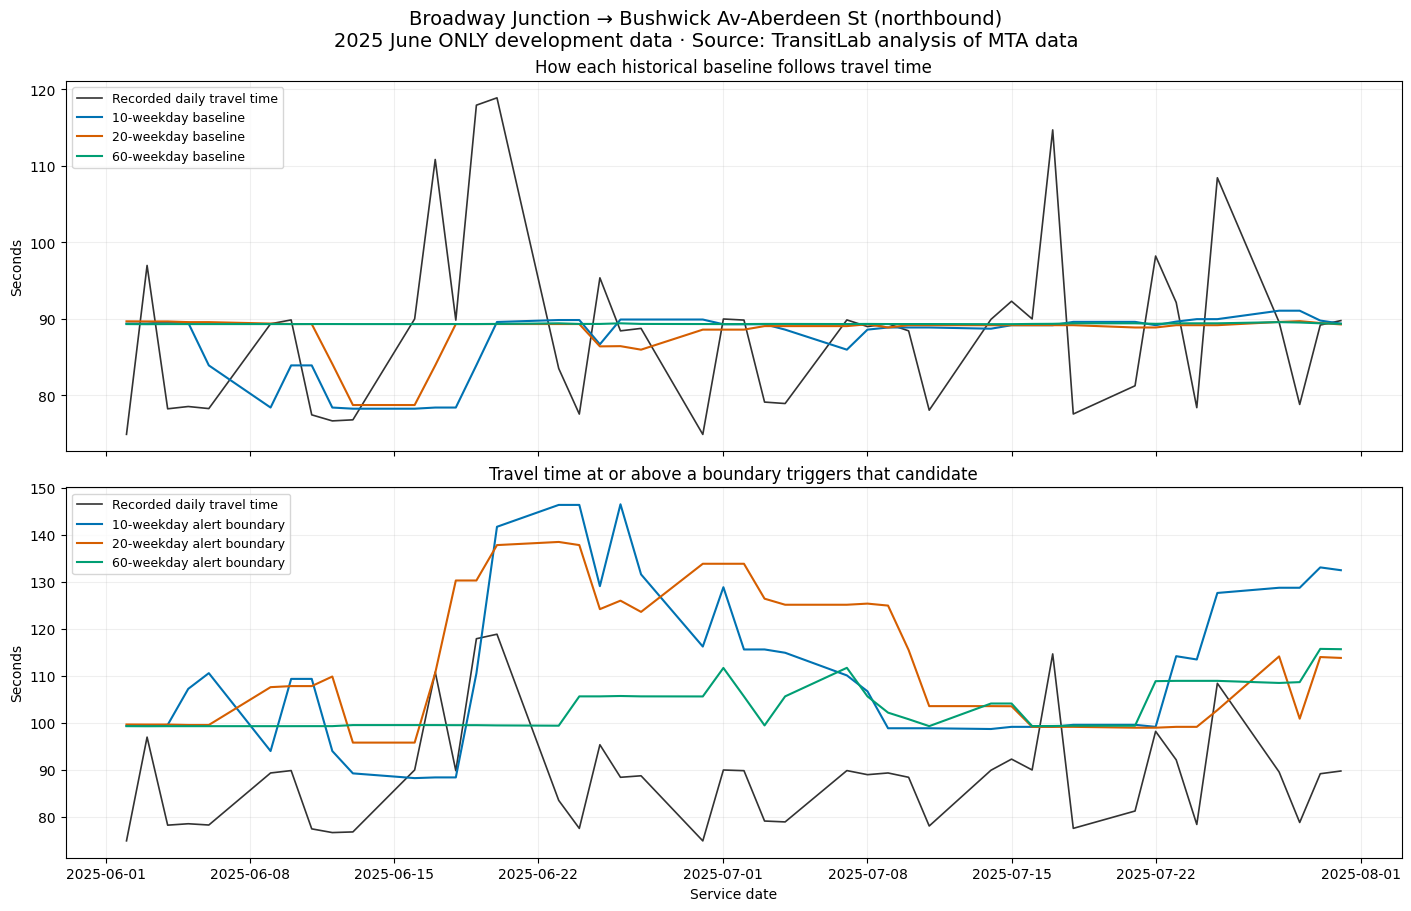

In [10]:
selected_a_stop = "L22N"
selected_b_stop = "L21N"

start_date = "2025-06-01"
end_date = "2025-07-31"

segment = candidates.loc[
    (candidates["a_stop"] == selected_a_stop)
    & (candidates["b_stop"] == selected_b_stop)
    & candidates["service_date"].between(start_date, end_date)
].copy()

if segment.empty:
    raise ValueError("No observations match the selected segment and dates.")

observed = (
    segment[["service_date", "travel_seconds"]]
    .drop_duplicates()
    .sort_values("service_date")
)

station_names = segment.iloc[0]

colors = {
    10: "#0072B2",
    20: "#D55E00",
    60: "#009E73",
}

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True,
    constrained_layout=True,
)

for axis in axes:
    axis.plot(
        observed["service_date"],
        observed["travel_seconds"],
        color="#333333",
        linewidth=1.2,
        label="Recorded daily travel time",
    )
    axis.set_ylabel("Seconds")
    axis.grid(alpha=0.2)

for window, color in colors.items():
    window_data = segment.loc[
        segment["baseline_window_weekdays"] == window
    ].sort_values("service_date")

    axes[0].plot(
        window_data["service_date"],
        window_data["baseline_seconds"],
        color=color,
        linewidth=1.5,
        label=f"{window}-weekday baseline",
    )

    axes[1].plot(
        window_data["service_date"],
        window_data["alert_boundary_seconds"],
        color=color,
        linewidth=1.5,
        label=f"{window}-weekday alert boundary",
    )

axes[0].set_title("How each historical baseline follows travel time")
axes[1].set_title("Travel time at or above a boundary triggers that candidate")
axes[1].set_xlabel("Service date")

for axis in axes:
    axis.legend(loc="upper left", fontsize=9)

fig.suptitle(
    f"{station_names['a_station']} → {station_names['b_station']} (northbound)\n"
    "2025 June ONLY development data · Source: TransitLab analysis of MTA data",
    fontsize=14,
)

plt.show()

### List the slow-day flags within the period shown on the chart.

In [11]:
shown = candidates.loc[
    (candidates["a_stop"] == "L22N")
    & (candidates["b_stop"] == "L21N")
    & candidates["service_date"].between("2025-06-01", "2025-07-31")
].copy()

flagged = shown.loc[
    shown["is_slow_day"].eq(True),
    [
        "service_date",
        "baseline_window_weekdays",
        "travel_seconds",
        "baseline_seconds",
        "slow_threshold_seconds",
        "alert_boundary_seconds",
    ],
].sort_values(["service_date", "baseline_window_weekdays"])

display(flagged.round(2))

,service_date,baseline_window_weekdays,travel_seconds,baseline_seconds,slow_threshold_seconds,alert_boundary_seconds
354,2025-06-16,10,90.00,78.26,10.00,88.26
357,2025-06-17,10,110.84,78.41,10.00,88.42
358,2025-06-17,20,110.84,83.92,26.73,110.66
359,2025-06-17,60,110.84,89.32,10.23,99.55
360,2025-06-18,10,89.84,78.41,10.00,88.42
363,2025-06-19,10,117.94,83.96,26.60,110.55
365,2025-06-19,60,117.94,89.33,10.21,99.54
368,2025-06-20,60,118.90,89.34,10.14,99.49
423,2025-07-17,10,114.71,89.18,10.00,99.18
424,2025-07-17,20,114.71,89.18,10.00,99.18


### How the baseline window changes the flags

For Broadway Junction to Bushwick Av-Aberdeen St northbound, the candidate
windows disagree during the June 2025 increase in travel time.

The 10-weekday baseline fell to roughly 78 seconds, while the 60 weekday
baseline remained around 89 seconds. As a result, travel times near 90 seconds
were flagged by the 10-day candidate on June 16 and 18, but remained below the
60-day candidate's boundary.

The opposite occurred on June 20. Travel time reached 118.90 seconds, but the
10 day candidate did not flag it because its alert boundary had risen above
that reading (When their is high variability the alert boundary rises). The 60 day 
candidate flagged the day against a boundary ofapproximately 99.49 seconds.

The 10 day candidate therefore produced four consecutive slow weekdays from
June 16–19. The 60 day candidate flagged June 17, 19, and 20, with June 18
interrupting the streak. These differences would change when a policy requiring
two or three consecutive slow weekdays produces an alert.

This example supports investigating both baseline length and the variability
threshold. A short window can respond to a recent fast period and can also
raise its alert boundary during variable conditions. Further development
examples are needed before selecting the final settings.

In [12]:
# Inspect both flagged and unflagged results around the boundary increase.
comparison = shown.loc[
    shown["service_date"].isin(
        pd.to_datetime(["2025-06-19", "2025-06-20"])
    ),
    [
        "service_date",
        "baseline_window_weekdays",
        "travel_seconds",
        "baseline_seconds",
        "slow_threshold_seconds",
        "alert_boundary_seconds",
        "is_slow_day",
    ],
].sort_values(["service_date", "baseline_window_weekdays"]).copy()

comparison["is_slow_day"] = (
    comparison["is_slow_day"]
    .map({True: "slow", False: "below threshold"})
    .fillna("unknown")
)

display(comparison.round(2))

,service_date,baseline_window_weekdays,travel_seconds,baseline_seconds,slow_threshold_seconds,alert_boundary_seconds,is_slow_day
363,2025-06-19,10,117.94,83.96,26.60,110.55,slow
364,2025-06-19,20,117.94,89.33,41.01,130.34,below threshold
365,2025-06-19,60,117.94,89.33,10.21,99.54,slow
366,2025-06-20,10,118.90,89.60,52.17,141.77,below threshold
367,2025-06-20,20,118.90,89.33,48.55,137.88,below threshold
368,2025-06-20,60,118.90,89.34,10.14,99.49,slow


The June 19–20 comparison shows how quickly the short window can change.
Travel time increased from 117.94 to 118.90 seconds, but the 10 weekday alert
boundary rose from 110.55 to 141.77 seconds. Most of that increase came from
the variability threshold, which rose from 26.60 to 52.17 seconds.

Consequently, the candidate stopped flagging even though travel time increased
The 60 weekday boundary stayed around 99.5 seconds and flagged both days
This example motivates checking whether rapid threshold changes hide
persistent slow running elsewhere in the development data

### Checking the same behavior on a second stretch

East 105 St → New Lots Av northbound had the most flagged days under every
baseline window. Here we inspect the same June–July period to see whether
rapid changes in the baseline or variability threshold also affect this stretch

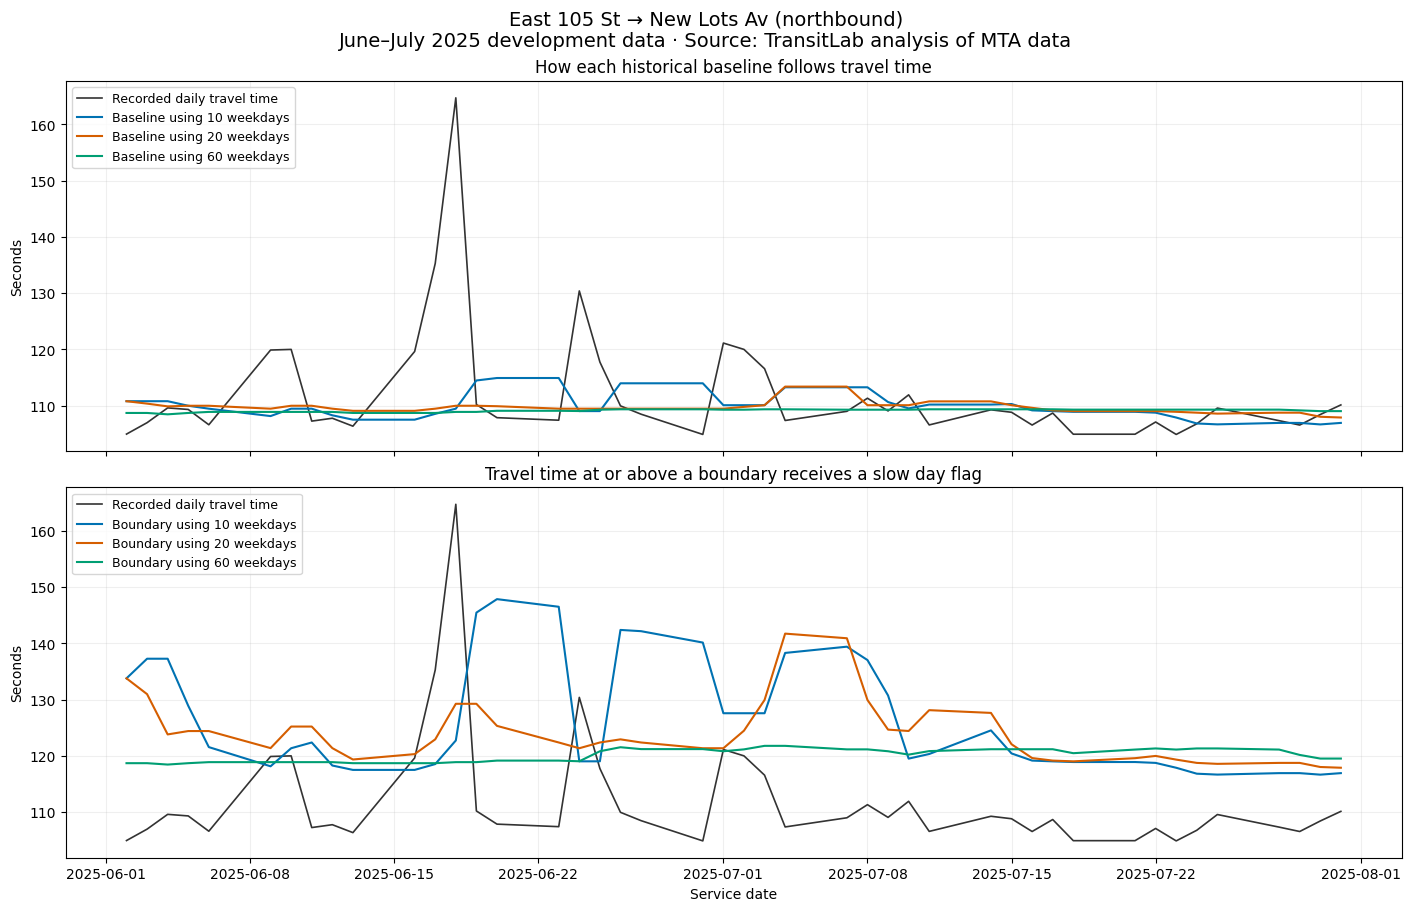

In [ ]:
# Inspect East 105 St -> New Lots Av northbound during June and July 2025

selected_a_stop = "L28N"
selected_b_stop = "L27N"

start_date = "2025-06-01"
end_date = "2025-07-31"

segment = candidates.loc[
    (candidates["a_stop"] == selected_a_stop)
    & (candidates["b_stop"] == selected_b_stop)
    & candidates["service_date"].between(start_date, end_date)
].copy()

if segment.empty:
    raise ValueError("No observations match the selected segment and dates.")

observed = (
    segment[["service_date", "travel_seconds"]]
    .drop_duplicates()
    .sort_values("service_date")
)

station_names = segment.iloc[0]

colors = {
    10: "#0072B2",
    20: "#D55E00",
    60: "#009E73",
}

fig, axes = plt.subplots(
    2,
    1,
    figsize=(14, 9),
    sharex=True,
    constrained_layout=True,
)

for axis in axes:
    axis.plot(
        observed["service_date"],
        observed["travel_seconds"],
        color="#333333",
        linewidth=1.2,
        label="Recorded daily travel time",
    )
    axis.set_ylabel("Seconds")
    axis.grid(alpha=0.2)

for window, color in colors.items():
    window_data = segment.loc[
        segment["baseline_window_weekdays"] == window
    ].sort_values("service_date")

    axes[0].plot(
        window_data["service_date"],
        window_data["baseline_seconds"],
        color=color,
        linewidth=1.5,
        label=f"Baseline using {window} weekdays",
    )

    axes[1].plot(
        window_data["service_date"],
        window_data["alert_boundary_seconds"],
        color=color,
        linewidth=1.5,
        label=f"Boundary using {window} weekdays",
    )

axes[0].set_title("How each historical baseline follows travel time")
axes[1].set_title("Travel time at or above a boundary receives a slow day flag")
axes[1].set_xlabel("Service date")

for axis in axes:
    axis.legend(loc="upper left", fontsize=9)

fig.suptitle(
    f"{station_names['a_station']} → {station_names['b_station']} (northbound)\n"
    "June–July 2025 development data · Source: TransitLab analysis of MTA data",
    fontsize=14,
)

plt.show()

The second stretch also shows that the variability threshold can drive
differences between candidates. The baselines remain relatively close, while
the shorter windows produce larger changes in the alert boundary.

The boundary using 60 weekdays stays around 119–122 seconds during this period.
The shorter windows sometimes require substantially higher travel times before
flagging a day because of the variability.

### Comparing detector sensitivity across all monitored stretches

Compare three baseline windows, minimum increases of 10, 15, and 20 seconds,
and variability multipliers of 2 and 3 using 2025 development data.

This comparison measures how much the settings change flag frequency


In [14]:
query = text("""
    SELECT
        service_date,
        a_stop,
        b_stop,
        baseline_window_weekdays,
        travel_seconds,
        baseline_seconds,
        mad_seconds
    FROM public.l_train_baseline_candidates
    WHERE analysis_period = 'development'
""")

with engine.connect() as connection:
    development = pd.read_sql_query(
        query,
        connection,
        parse_dates=["service_date"],
    )

# Test a small grid of settings around our initial choices.
settings = pd.MultiIndex.from_product(
    [[10.0, 15.0, 20.0], [2.0, 3.0]],
    names=["minimum_extra_seconds", "variation_multiplier"],
).to_frame(index=False)

sensitivity = development.merge(settings, how="cross")

sensitivity["threshold_seconds"] = (
    sensitivity["variation_multiplier"]
    * 1.4826
    * sensitivity["mad_seconds"]
).clip(lower=sensitivity["minimum_extra_seconds"])

scoreable = sensitivity[
    ["travel_seconds", "baseline_seconds", "mad_seconds"]
].notna().all(axis=1)

sensitivity["is_slow_day"] = (
    (
        sensitivity["travel_seconds"] - sensitivity["baseline_seconds"]
        >= sensitivity["threshold_seconds"]
    )
    .astype("boolean")
    .mask(~scoreable)
)

summary = (
    sensitivity.groupby(
        [
            "baseline_window_weekdays",
            "minimum_extra_seconds",
            "variation_multiplier",
        ]
    )
    .agg(
        segment_days=("is_slow_day", "size"),
        scoreable_days=("is_slow_day", "count"),
        slow_days=("is_slow_day", "sum"),
    )
    .reset_index()
)

summary["slow_pct"] = (
    100 * summary["slow_days"] / summary["scoreable_days"]
).round(2)

display(summary)

,baseline_window_weekdays,minimum_extra_seconds,variation_multiplier,segment_days,scoreable_days,slow_days,slow_pct
0,10,10.0,2.0,11484,11479,674,5.87
1,10,10.0,3.0,11484,11479,624,5.44
2,10,15.0,2.0,11484,11479,252,2.2
3,10,15.0,3.0,11484,11479,233,2.03
4,10,20.0,2.0,11484,11479,166,1.45
5,10,20.0,3.0,11484,11479,151,1.32
6,20,10.0,2.0,11484,11479,693,6.04
7,20,10.0,3.0,11484,11479,609,5.31
8,20,15.0,2.0,11484,11479,266,2.32
9,20,15.0,3.0,11484,11479,245,2.13


### What was found?

The settings greatly change which days the detector flags. Raising the
minimum increase (flag for slow_days) from 10 to 15 seconds removed many flags. Reducing the
variability multiplier added flags.

We have not selected the best settings yet. Next, we will group slowdowns into
episodes and measure whether the flags catch persistent problems or mainly
identify spikes that clear quickly.